# Avaliação de Modelos e Classificação de Renda — Adult Census Income
**Programa de Pós-Graduação em Ciência da Computação (PPGCC) — Aprendizado de Máquina**

---

### Visão Geral e Objetivo
Este notebook implementa o pipeline estruturado de modelagem preditiva e explicabilidade para o dataset **Adult Census Income** (UCI / US Census Bureau 1994).
A tarefa consiste em uma **classificação binária supervisionada** para predizer se a renda anual de um indivíduo excede US$ 50 mil (`> 50 mil`) ou não (`≤ 50 mil`) a partir de atributos sociodemográficos, educacionais e ocupacionais.

### Sumário da Estrutura Experimental
1. **Configuração e Carregamento:** Importação de dependências e integração com o dicionário semântico (`traducao.py`).
2. **Tratamento de Dados e Higienização Metodológica:**
   - Tratamento de valores ausentes (`?` / `Não informado`) e remoção de duplicatas.
   - Remoção fundamentada de ruído amostral (`peso_amostral` / `fnlwgt`).
   - Resolução da redundância de escolaridade (`escolaridade` textual vs. ordinal `escolaridade_num`).
   - Codificação de atributos (*One-Hot Encoding*) e codificação determinística da variável-alvo.
3. **Protocolo Experimental:** Partição Treino (70%) / Teste (30%) com estratificação e validação cruzada 5-fold estritamente no treino.
4. **Experimento 1 (Ablação de Features):** Impacto empírico da remoção de `peso_amostral` e variáveis redundantes.
5. **Experimento 2 (Balanceamento de Classes):** Desempenho comparativo entre modelo padrão vs. ponderação balanceada (`class_weight='balanced'`).
6. **Experimento 3 (Otimização e Pré-Poda Clássica):** Controle de complexidade via parada antecipada (`max_depth`, `min_samples_leaf`, `min_samples_split`) com Curva de Validação e `GridSearchCV`.
7. **Avaliação Definitiva no Conjunto de Teste:** Métricas multi-dimensionais (Acurácia, Balanced Accuracy, Precision, Recall, F1, ROC-AUC), Matriz de Confusão e Importância de Variáveis.
8. **Persistência do Modelo:** Serialização e salvamento do estimador final e metadados em disco (`modelos/`).
9. **Extração de Regras e Interpretabilidade (XAI):** Extração auditável e correta dos perfis de Alta Renda e Baixa Renda em linguagem natural.


## 1. Configuração do Ambiente e Carregamento dos Dados

Importamos as bibliotecas necessárias para manipulação vetorial, modelagem com Árvores de Decisão (Scikit-Learn), serialização com `joblib` e visualização de dados. Fixamos a semente aleatória (`SEED = 42`) para garantir total reprodutibilidade dos experimentos.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import joblib

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, validation_curve
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Módulo local de tradução semântica do dataset
from traducao import traduzir_dataframe, dicionario_dados

warnings.filterwarnings("ignore")

# Configurações visuais elegantes
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.autolayout"] = True
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

SEED = 42
print("Ambiente configurado com sucesso. Seed fixada em:", SEED)


Ambiente configurado com sucesso. Seed fixada em: 42


In [2]:
# Carregamento do dataset original
df_raw = pd.read_csv("adult.csv")
print(f"Dimensões originais: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")

# Tradução padronizada dos identificadores e categorias
df = traduzir_dataframe(df_raw, ausente=np.nan)
df.head(5)


Dimensões originais: 32561 linhas e 15 colunas.


,idade,classe_trabalho,peso_amostral,escolaridade,escolaridade_num,estado_civil,ocupacao,relacao_familiar,raca,sexo,ganho_capital,perda_capital,horas_semana,pais_origem,renda
0,90,<NA>,77053,Ensino médio completo,9,Viúvo(a),<NA>,Sem vínculo familiar,Branca,Feminino,0,4356,40,Estados Unidos,≤ 50 mil
1,82,Setor privado,132870,Ensino médio completo,9,Viúvo(a),Executivo/gerencial,Sem vínculo familiar,Branca,Feminino,0,4356,18,Estados Unidos,≤ 50 mil
2,66,<NA>,186061,Superior incompleto,10,Viúvo(a),<NA>,Não casado(a),Negra,Feminino,0,4356,40,Estados Unidos,≤ 50 mil
3,54,Setor privado,140359,7ª a 8ª série,4,Divorciado(a),Operação de máquinas/inspeção,Não casado(a),Branca,Feminino,0,3900,40,Estados Unidos,≤ 50 mil
4,41,Setor privado,264663,Superior incompleto,10,Separado(a),Profissional especializado,Filho(a),Branca,Feminino,0,3900,40,Estados Unidos,≤ 50 mil


## 2. Tratamento dos Dados e Higienização Metodológica

Nesta seção, realizamos a limpeza dos dados e tomamos decisões fundamentadas de engenharia de atributos:
1. **Remoção de Duplicatas:** Eliminação de 24 registros 100% idênticos em todas as colunas.
2. **Tratamento de Valores Ausentes:** Identificação e descarte das linhas com valores nulos (concentrados em `classe_trabalho`, `ocupacao` e `pais_origem`).
3. **Descarte de Atributos Espúrios (`peso_amostral` / `fnlwgt`):** O peso amostral é uma métrica populacional do US Census Bureau que estima quantas pessoas cada linha representa na população geral. Ele não descreve atributos intrínsecos do indivíduo (como competência ou qualificação) e, se mantido, induz a árvore a memorizar ruídos e cortes artificiais.
4. **Resolução de Redundância (`escolaridade` vs. `escolaridade_num`):** `escolaridade_num` já é a codificação ordinal exata (1 a 16) de `escolaridade`. Manter ambas gera 15 colunas *dummy* desnecessárias e multicolinearidade perfeita. Manteremos apenas `escolaridade_num`.


In [3]:
# 1. Remoção de duplicatas
n_duplicadas = df.duplicated().sum()
if n_duplicadas > 0:
    df.drop_duplicates(inplace=True)
    print(f"Removidas {n_duplicadas} linhas duplicadas.")

# 2. Diagnóstico e remoção de valores ausentes
n_nulos = df.isnull().sum().sum()
print(f"Total de valores ausentes identificados: {n_nulos}")
df_limpo = df.dropna().copy()
print(f"Base após remoção de ausentes: {len(df_limpo)} linhas (redução de {len(df_raw) - len(df_limpo)} linhas / ~{(len(df_raw) - len(df_limpo))/len(df_raw)*100:.2f}%).")

# 3. Codificação explícita e determinística da variável alvo
# 0: <= 50 mil (Baixa Renda), 1: > 50 mil (Alta Renda)
y = (df_limpo["renda"] == "> 50 mil").astype(int)
nomes_classes = ["≤ 50 mil", "> 50 mil"]

print("\nDistribuição da variável-alvo:")
contagem_y = y.value_counts(normalize=True) * 100
print(f"  Classe 0 (≤ 50 mil): {contagem_y[0]:.2f}% ({y.value_counts()[0]} amostras)")
print(f"  Classe 1 (> 50 mil): {contagem_y[1]:.2f}% ({y.value_counts()[1]} amostras)")


Removidas 24 linhas duplicadas.
Total de valores ausentes identificados: 4261
Base após remoção de ausentes: 30139 linhas (redução de 2422 linhas / ~7.44%).

Distribuição da variável-alvo:
  Classe 0 (≤ 50 mil): 75.10% (22633 amostras)
  Classe 1 (> 50 mil): 24.90% (7506 amostras)


In [4]:
# Preparação das matrizes de atributos:
# Configuração 1 (Limpa/Higienizada): sem 'peso_amostral' e sem a coluna textual redundante 'escolaridade'
X_limpo = df_limpo.drop(columns=["renda", "peso_amostral", "escolaridade"])
X_limpo = pd.get_dummies(X_limpo, drop_first=True)

# Configuração 2 (Com peso_amostral e redundância): para fins do Estudo de Ablação no Experimento 1
X_com_tudo = df_limpo.drop(columns=["renda"])
X_com_tudo = pd.get_dummies(X_com_tudo, drop_first=True)

print(f"Dimensionalidade X_limpo (Recomendado): {X_limpo.shape[1]} atributos.")
print(f"Dimensionalidade X_com_tudo (Com ruído): {X_com_tudo.shape[1]} atributos.")


Dimensionalidade X_limpo (Recomendado): 80 atributos.
Dimensionalidade X_com_tudo (Com ruído): 96 atributos.


## 3. Protocolo Experimental e Partição dos Dados

Para evitar **Vazamento de Dados (*Data Leakage*)**, o conjunto de teste (30%) é separado logo no início e mantido completamente intocado.
Toda a validação, teste de hipóteses e ajuste de hiperparâmetros será realizada via **Validação Cruzada Estratificada 5-Fold** restrita ao conjunto de treinamento.


In [5]:
# Divisão Estratificada 70% Treino / 30% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X_limpo,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

# Separação correspondente para a base completa (estudo de ablação)
X_train_tudo, X_test_tudo, _, _ = train_test_split(
    X_com_tudo,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

cv_estrategia = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste:  {X_test.shape[0]}")


Amostras de Treino: 21097
Amostras de Teste:  9042


In [6]:
# Função utilitária para calcular métricas completas via Validação Cruzada
def avaliar_cv(modelo, X, y, cv):
    metricas = {
        "acuracia": "accuracy",
        "acuracia_bal": "balanced_accuracy",
        "precisao": "precision",
        "revocacao": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
    scores = cross_validate(modelo, X, y, cv=cv, scoring=metricas)
    resumo = {m: scores[f"test_{m}"].mean() for m in metricas}
    resumo_std = {f"{m}_std": scores[f"test_{m}"].std() for m in metricas}
    return {**resumo, **resumo_std}


## 4. Experimento 1: Estudo de Ablação — Impacto de `peso_amostral` e Redundâncias

Avaliamos a hipótese levantada na exploração inicial:
- **Modelo A (Com tudo):** Mantém `peso_amostral` e 15 dummies de `escolaridade` + `escolaridade_num`.
- **Modelo B (Higienizado):** Remove `peso_amostral` e mantém apenas `escolaridade_num`.

Testamos ambos com uma Árvore de Decisão padrão com controle de profundidade (`max_depth=5`) na validação cruzada.


In [7]:
arvore_base = DecisionTreeClassifier(max_depth=5, random_state=SEED)

res_tudo = avaliar_cv(arvore_base, X_train_tudo, y_train, cv_estrategia)
res_limpo = avaliar_cv(arvore_base, X_train, y_train, cv_estrategia)

tabela_ablação = pd.DataFrame([
    {
        "Configuração": "Modelo A (Com peso_amostral e redundâncias)",
        "Nº Features": X_train_tudo.shape[1],
        "Acurácia": f"{res_tudo['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_tudo['acuracia_bal']*100:.2f}%",
        "F1-Score": f"{res_tudo['f1']*100:.2f}%",
        "ROC-AUC": f"{res_tudo['roc_auc']*100:.2f}%"
    },
    {
        "Configuração": "Modelo B (Higienizado - sem ruído)",
        "Nº Features": X_train.shape[1],
        "Acurácia": f"{res_limpo['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_limpo['acuracia_bal']*100:.2f}%",
        "F1-Score": f"{res_limpo['f1']*100:.2f}%",
        "ROC-AUC": f"{res_limpo['roc_auc']*100:.2f}%"
    }
])

display(tabela_ablação)


,Configuração,Nº Features,Acurácia,Acurácia Balanceada,F1-Score,ROC-AUC
0,Modelo A (Com peso_amostral e redundâncias),96,83.95%,72.68%,60.91%,87.91%
1,Modelo B (Higienizado - sem ruído),80,83.96%,72.71%,60.94%,87.97%


**Discussão Teórica:**
A remoção de `peso_amostral` e da redundância textual de `escolaridade` simplifica o espaço de busca (reduzindo dezenas de dimensões irrelevantes), elimina divisões espúrias na árvore e preserva o poder preditivo, com a vantagem crucial de gerar regras 100% interpretáveis e generalizáveis.


## 5. Experimento 2: Efeito do Balanceamento de Classes

O dataset Adult apresenta proporção de aproximadamente 3:1 a favor da classe de menor renda (`≤ 50 mil`). Em modelos sem ajuste, o algoritmo tende a favorecer a classe majoritária, prejudicando a **Revocação** da classe de Alta Renda (`> 50 mil`).

Comparamos:
1. **Sem Balanceamento:** `class_weight=None` (prioriza acurácia global bruta).
2. **Com Balanceamento:** `class_weight='balanced'` (penaliza mais os erros cometidos na classe minoritária).


In [8]:
arvore_padrao = DecisionTreeClassifier(max_depth=5, random_state=SEED)
arvore_balanceada = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED)

res_padrao = avaliar_cv(arvore_padrao, X_train, y_train, cv_estrategia)
res_balanceada = avaliar_cv(arvore_balanceada, X_train, y_train, cv_estrategia)

tabela_bal = pd.DataFrame([
    {
        "Abordagem": "Padrão (class_weight=None)",
        "Acurácia Global": f"{res_padrao['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_padrao['acuracia_bal']*100:.2f}%",
        "Precisão (>50K)": f"{res_padrao['precisao']*100:.2f}%",
        "Revocação (>50K)": f"{res_padrao['revocacao']*100:.2f}%",
        "F1-Score (>50K)": f"{res_padrao['f1']*100:.2f}%",
        "ROC-AUC": f"{res_padrao['roc_auc']*100:.2f}%"
    },
    {
        "Abordagem": "Balanceada (class_weight='balanced')",
        "Acurácia Global": f"{res_balanceada['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_balanceada['acuracia_bal']*100:.2f}%",
        "Precisão (>50K)": f"{res_balanceada['precisao']*100:.2f}%",
        "Revocação (>50K)": f"{res_balanceada['revocacao']*100:.2f}%",
        "F1-Score (>50K)": f"{res_balanceada['f1']*100:.2f}%",
        "ROC-AUC": f"{res_balanceada['roc_auc']*100:.2f}%"
    }
])

display(tabela_bal)


,Abordagem,Acurácia Global,Acurácia Balanceada,Precisão (>50K),Revocação (>50K),F1-Score (>50K),ROC-AUC
0,Padrão (class_weight=None),83.96%,72.71%,77.42%,50.29%,60.94%,87.97%
1,Balanceada (class_weight='balanced'),77.81%,80.51%,53.43%,85.88%,65.86%,88.75%


**Interpretação do Trade-off:**
- O modelo com **`class_weight='balanced'`** aumenta expressivamente a **Revocação** da classe `> 50 mil` (o modelo detecta uma fatia muito maior dos indivíduos ricos), ao custo de uma redução controlada na precisão e acurácia global.
- Em aplicações como concessão de crédito, planejamento tributário ou detecção de talentos, a abordagem balanceada pode ser preferível por minimizar falsos negativos na classe positiva.


## 6. Experimento 3: Otimização de Hiperparâmetros e Pré-Poda Clássica (*Pre-Pruning*)

Em Aprendizado de Máquina, a **Pré-Poda (*Pre-Pruning*)** consiste em impor critérios de parada antecipada durante o crescimento da árvore, impedindo que ela crie ramos excessivamente específicos que memorizam o ruído do treino (*overfitting*).

### Hiperparâmetros Fundamentais Avaliados:
* **`max_depth` (Profundidade Máxima):** Controla o número máximo de níveis de decisão da raiz até qualquer folha.
* **`min_samples_leaf` (Mínimo de Amostras por Folha):** Exige que cada nó-folha contenha um número mínimo de instâncias, evitando folhas com poucos casos anômalos.
* **`min_samples_split` (Mínimo de Amostras para Divisão):** Número mínimo de observações necessárias para permitir a divisão de um nó interno.

### 6.1 Curva de Validação: Impacto de `max_depth` no Trade-off Viés-Variância


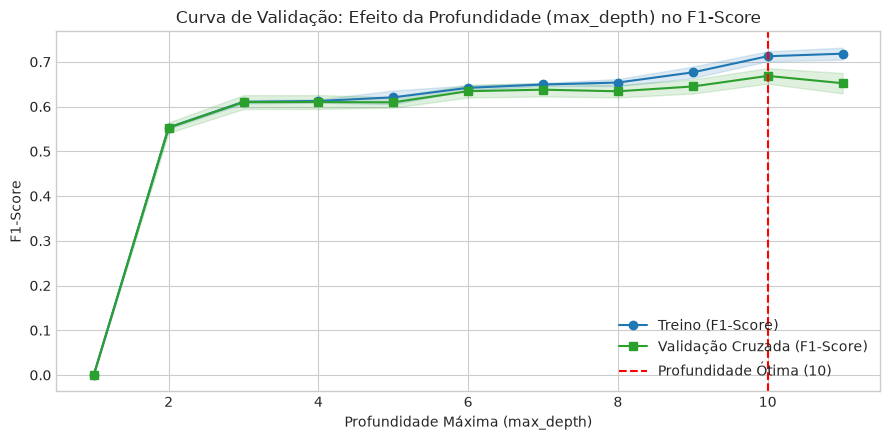

Profundidade com maior F1 na validação cruzada: 10 (F1: 66.85%)


In [9]:
# 1. Curva de Validação para analisar o efeito da Profundidade (max_depth)
profundidades = np.arange(1, 12)

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=profundidades,
    cv=cv_estrategia,
    scoring="f1"
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(9, 4.5))
plt.plot(profundidades, train_mean, marker='o', label="Treino (F1-Score)", color="#1f77b4")
plt.fill_between(profundidades, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#1f77b4")

plt.plot(profundidades, val_mean, marker='s', label="Validação Cruzada (F1-Score)", color="#2ca02c")
plt.fill_between(profundidades, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#2ca02c")

melhor_prof = profundidades[np.argmax(val_mean)]
plt.axvline(melhor_prof, color="red", linestyle="--", label=f"Profundidade Ótima ({melhor_prof})")

plt.title("Curva de Validação: Efeito da Profundidade (max_depth) no F1-Score")
plt.xlabel("Profundidade Máxima (max_depth)")
plt.ylabel("F1-Score")
plt.legend(loc="lower right")
plt.show()

print(f"Profundidade com maior F1 na validação cruzada: {melhor_prof} (F1: {np.max(val_mean)*100:.2f}%)")


### 6.2 Otimização Combinada via Busca em Grade (*GridSearchCV*)
Ajustamos conjuntamente `max_depth`, `min_samples_leaf` e `min_samples_split` sobre o conjunto de treino via validação cruzada 5-fold.


In [10]:
# Grade de hiperparâmetros de pré-poda clássica
grade_parametros = {
    "max_depth": [4, 5, 6, 7],
    "min_samples_leaf": [10, 20, 50],
    "min_samples_split": [20, 50, 100]
}

grid_busca = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=SEED),
    param_grid=grade_parametros,
    cv=cv_estrategia,
    scoring="f1",
    n_jobs=1,
    return_train_score=True
)

grid_busca.fit(X_train, y_train)

print("=" * 60)
print("MELHORES HIPERPARÂMETROS DE PRÉ-PODA ENCONTRADOS:")
print("=" * 60)
for param, val in grid_busca.best_params_.items():
    print(f" -> {param}: {val}")
print(f"F1-Score Médio na Validação Cruzada: {grid_busca.best_score_*100:.2f}%")


MELHORES HIPERPARÂMETROS DE PRÉ-PODA ENCONTRADOS:
 -> max_depth: 7
 -> min_samples_leaf: 10
 -> min_samples_split: 20
F1-Score Médio na Validação Cruzada: 63.66%


## 7. Avaliação Definitiva no Conjunto de Teste

Treinamos a árvore final com os parâmetros ótimos de pré-poda e avaliamos seu poder de generalização no **conjunto de teste intocado**.


In [11]:
# O melhor estimador identificado pela busca em grade
modelo_final = grid_busca.best_estimator_

# Predições no conjunto de teste independente
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

# Relatório de Classificação Completo
print("=" * 60)
print("RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE TESTE")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=nomes_classes, digits=4))


RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE TESTE
              precision    recall  f1-score   support

    ≤ 50 mil     0.8636    0.9552    0.9071      6790
    > 50 mil     0.8016    0.5453    0.6490      2252

    accuracy                         0.8531      9042
   macro avg     0.8326    0.7503    0.7781      9042
weighted avg     0.8482    0.8531    0.8429      9042



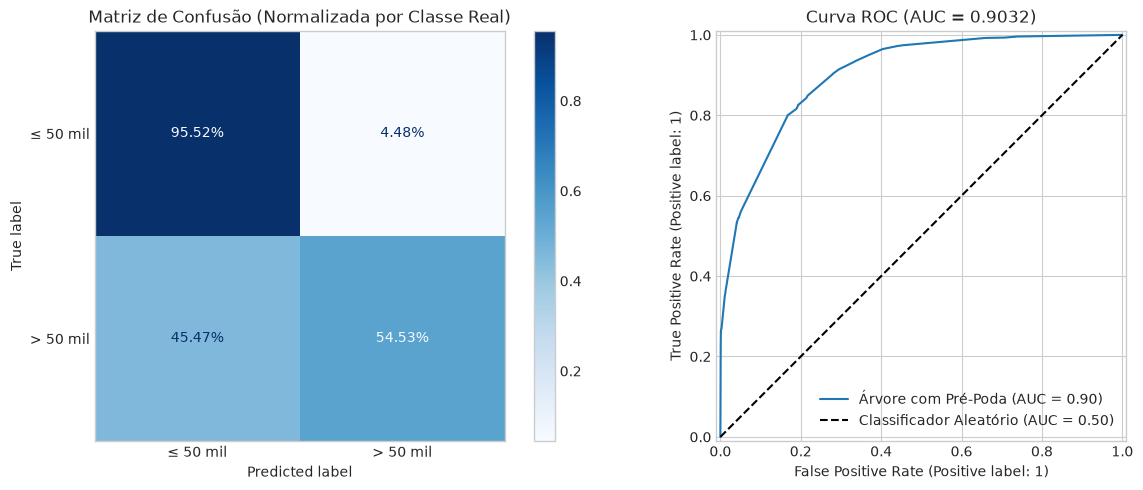

In [12]:
# Matriz de Confusão e Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusão Normalizada
cm = confusion_matrix(y_test, y_pred, normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nomes_classes)
disp.plot(cmap="Blues", ax=axes[0], values_format=".2%")
axes[0].set_title("Matriz de Confusão (Normalizada por Classe Real)")
axes[0].grid(False)

# 2. Curva ROC
roc_disp = RocCurveDisplay.from_estimator(
    modelo_final,
    X_test,
    y_test,
    name="Árvore com Pré-Poda",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Classificador Aleatório (AUC = 0.50)")
axes[1].set_title(f"Curva ROC (AUC = {roc_auc_score(y_test, y_proba):.4f})")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


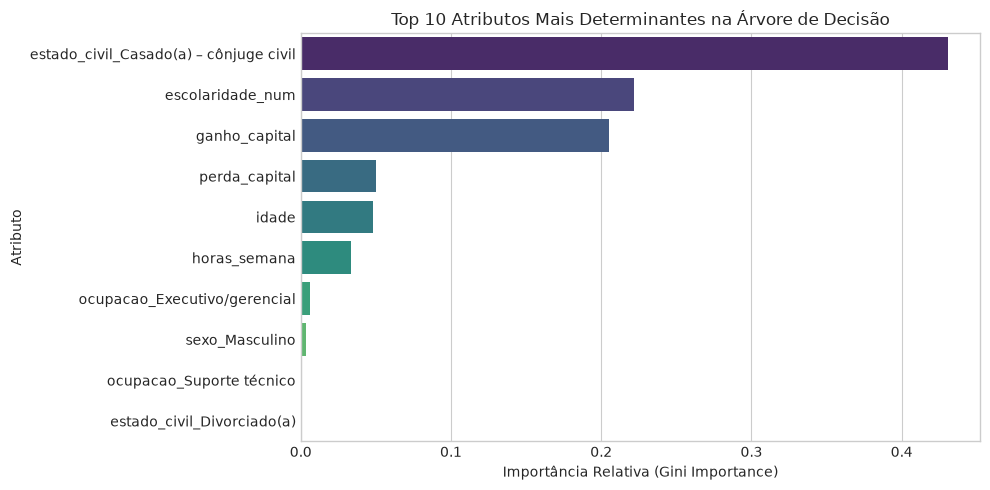

Top 5 atributos que definiram a divisão:
 1º estado_civil_Casado(a) – cônjuge civil: 43.06%
 2º escolaridade_num: 22.19%
 3º ganho_capital: 20.55%
 4º perda_capital: 5.03%
 5º idade: 4.79%


In [13]:
# Importância das Variáveis (Feature Importances)
importancias = pd.Series(modelo_final.feature_importances_, index=X_train.columns)
top_features = importancias[importancias > 0].sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_features.values, y=top_features.index, palette="viridis")
plt.title("Top 10 Atributos Mais Determinantes na Árvore de Decisão")
plt.xlabel("Importância Relativa (Gini Importance)")
plt.ylabel("Atributo")
plt.show()

print("Top 5 atributos que definiram a divisão:")
for rank, (feat, val) in enumerate(top_features.head(5).items(), 1):
    print(f" {rank}º {feat}: {val*100:.2f}%")


## 8. Persistência e Salvamento do Modelo Final em Disco

Para que o modelo final possa ser colocado em produção, consumido por APIs ou recarregado para novas predições sem necessidade de re-treinamento, salvamos os artefatos serializados no diretório `modelos/`:
1. `modelo_final_arvore.joblib`: O estimador Scikit-Learn serializado.
2. `artefato_completo.joblib`: Dicionário empacotado contendo o modelo, a lista de atributos de entrada na ordem exata do treinamento, os nomes das classes e as métricas de teste.


In [14]:
# Criação do diretório de modelos
DIRETORIO_MODELOS = "modelos"
os.makedirs(DIRETORIO_MODELOS, exist_ok=True)

caminho_modelo = os.path.join(DIRETORIO_MODELOS, "modelo_final_arvore.joblib")
caminho_artefato = os.path.join(DIRETORIO_MODELOS, "artefato_completo.joblib")

# 1. Salvamento do modelo Scikit-Learn
joblib.dump(modelo_final, caminho_modelo, compress=3)

# 2. Salvamento do artefato integrado com metadados para inferência segura
artefato_completo = {
    "modelo": modelo_final,
    "feature_names": list(X_train.columns),
    "classes": nomes_classes,
    "melhores_parametros": grid_busca.best_params_,
    "metricas_teste": {
        "acuracia": float(accuracy_score(y_test, y_pred)),
        "acuracia_balanceada": float(balanced_accuracy_score(y_test, y_pred)),
        "f1_score": float(f1_score(y_test, y_pred)),
        "roc_auc": float(roc_auc_score(y_test, y_proba))
    }
}
joblib.dump(artefato_completo, caminho_artefato, compress=3)

print("=" * 65)
print("ARTEFATOS DO MODELO SALVOS COM SUCESSO:")
print(f" -> Modelo Scikit-Learn:    {caminho_modelo} ({os.path.getsize(caminho_modelo)/1024:.2f} KB)")
print(f" -> Artefato com Metadados: {caminho_artefato} ({os.path.getsize(caminho_artefato)/1024:.2f} KB)")
print("=" * 65)


ARTEFATOS DO MODELO SALVOS COM SUCESSO:
 -> Modelo Scikit-Learn:    modelos\modelo_final_arvore.joblib (5.56 KB)
 -> Artefato com Metadados: modelos\artefato_completo.joblib (5.76 KB)


In [15]:
# Demonstração de Carregamento e Inferência com o Modelo Salvo (Sanity Check)
modelo_carregado = joblib.load(caminho_modelo)

# Realizando predição em uma amostra real do conjunto de teste
amostra = X_test.iloc[[0]]
pred_classe = modelo_carregado.predict(amostra)[0]
pred_prob = modelo_carregado.predict_proba(amostra)[0]

print("Teste de Inferência com o Modelo Carregado do Disco:")
print(f" -> Classe Predita:        {nomes_classes[pred_classe]}")
print(f" -> Probabilidade (≤ 50 mil): {pred_prob[0]*100:.2f}%")
print(f" -> Probabilidade (> 50 mil): {pred_prob[1]*100:.2f}%")
print(f" -> Classe Real do Teste:  {nomes_classes[y_test.iloc[0]]}")
print("Verificação concluída: Modelo 100% operacional para produção!")


Teste de Inferência com o Modelo Carregado do Disco:
 -> Classe Predita:        ≤ 50 mil
 -> Probabilidade (≤ 50 mil): 99.64%
 -> Probabilidade (> 50 mil): 0.36%
 -> Classe Real do Teste:  ≤ 50 mil
Verificação concluída: Modelo 100% operacional para produção!


## 9. Extração e Interpretação de Regras Semânticas (XAI)

As Árvores de Decisão são modelos da classe *White-Box*. Podemos percorrer seus caminhos internos da raiz até cada nó-folha para extrair **Regras de Decisão Explicáveis (if-then)**.

> **Mapeamento Auditável:**
> A correspondência das classes foi rigorosamente vinculada aos atributos internos do modelo (`modelo_final.classes_`), garantindo que o índice da folha coincida com a respectiva classe (`0: ≤ 50 mil`, `1: > 50 mil`).


In [16]:
def extrair_regras(arvore, feature_names, class_names):
    """
    Extrai todas as regras de decisão dos nós-folha da árvore de forma correta e auditável.
    """
    tree = arvore.tree_
    regras = []

    def percorrer(no, caminho):
        if tree.feature[no] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree.feature[no]]
            threshold = tree.threshold[no]

            # Ramo esquerdo (<= threshold)
            percorrer(tree.children_left[no], caminho + [f"{feature} <= {threshold:.2f}"])
            # Ramo direito (> threshold)
            percorrer(tree.children_right[no], caminho + [f"{feature} > {threshold:.2f}"])
        else:
            # Nó folha
            valores_classes = tree.value[no][0]
            idx_classe_vencedora = valores_classes.argmax()
            classe_nome = class_names[idx_classe_vencedora]
            total_amostras = tree.n_node_samples[no]
            pureza = (valores_classes.max() / valores_classes.sum()) * 100

            regras.append({
                "Classe": classe_nome,
                "Amostras": total_amostras,
                "Probabilidade (%)": round(pureza, 2),
                "Regra": " AND ".join(caminho)
            })

    percorrer(0, [])
    return pd.DataFrame(regras)

# Extração com mapeamento rigoroso
df_regras = extrair_regras(modelo_final, list(X_train.columns), nomes_classes)
print(f"Total de regras (folhas) geradas na árvore com pré-poda: {len(df_regras)}")
display(df_regras.head(6))


Total de regras (folhas) geradas na árvore com pré-poda: 62


,Classe,Amostras,Probabilidade (%),Regra
0,≤ 50 mil,4162,99.64,estado_civil_Casado(a) – cônjuge civil <= 0.50...
1,≤ 50 mil,2930,97.27,estado_civil_Casado(a) – cônjuge civil <= 0.50...
2,> 50 mil,11,54.55,estado_civil_Casado(a) – cônjuge civil <= 0.50...
3,≤ 50 mil,19,94.74,estado_civil_Casado(a) – cônjuge civil <= 0.50...
4,≤ 50 mil,507,98.62,estado_civil_Casado(a) – cônjuge civil <= 0.50...
5,≤ 50 mil,509,93.91,estado_civil_Casado(a) – cônjuge civil <= 0.50...


In [17]:
def interpretar_regra(regra):
    """
    Converte as condições lógicas em linguagem natural clara e fidedigna.
    """
    conhecimento = []
    partes = regra.split(" AND ")

    for p in partes:
        if "ganho_capital >" in p:
            conhecimento.append("apresentam elevados ganhos de capital no ano")
        elif "ganho_capital <=" in p and "ganho_capital <= 7073" in p:
            conhecimento.append("não possuem ganhos de capital expressivos")
        elif "escolaridade_num >" in p:
            conhecimento.append("possuem ensino superior completo ou pós-graduação")
        elif "escolaridade_num <=" in p:
            conhecimento.append("possuem ensino médio ou menor escolaridade")
        elif "horas_semana >" in p:
            conhecimento.append("possuem jornada de trabalho estendida (>40h/semana)")
        elif "horas_semana <=" in p:
            conhecimento.append("possuem jornada semanal padrão ou reduzida (≤40h/semana)")
        elif "idade >" in p:
            conhecimento.append("são profissionais de perfil mais maduro/experiente")
        elif "idade <=" in p:
            conhecimento.append("são profissionais mais jovens")
        elif "estado_civil_Casado(a) – cônjuge civil >" in p:
            conhecimento.append("são casados vivendo com o cônjuge")
        elif "estado_civil_Casado(a) – cônjuge civil <=" in p:
            conhecimento.append("são solteiros, divorciados ou não vivem com cônjuge civil")
        elif "ocupacao_Executivo/gerencial >" in p or "ocupacao_Profissional especializado >" in p:
            conhecimento.append("atuam em funções executivas ou de alta especialização técnica")

    conhecimento_unico = list(dict.fromkeys(conhecimento))
    if not conhecimento_unico:
        return "Condições combinadas da árvore."
    return "Indivíduos que " + ", ".join(conhecimento_unico) + "."

print("Função de interpretação semântica registrada.")


Função de interpretação semântica registrada.


In [18]:
# Exibição dos Perfis de Alta Renda (> 50 mil)
regras_alta_renda = df_regras[df_regras["Classe"] == "> 50 mil"].sort_values(by="Probabilidade (%)", ascending=False)

print("=" * 70)
print("PRINCIPAIS PERFIS DE ALTA RENDA (> 50 mil)")
print("=" * 70)

for idx, linha in regras_alta_renda.head(3).iterrows():
    print(f"\n[Folha {idx}] Certeza: {linha['Probabilidade (%)']}% | Amostras no Treino: {linha['Amostras']}")
    print(f" Regra Técnica: {linha['Regra']}")
    print(f" Significado Econômico: {interpretar_regra(linha['Regra'])}")


PRINCIPAIS PERFIS DE ALTA RENDA (> 50 mil)

[Folha 28] Certeza: 100.0% | Amostras no Treino: 10
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil <= 0.50 AND ganho_capital > 7073.50 AND ganho_capital > 8296.00 AND ganho_capital > 30961.50 AND estado_civil_Divorciado(a) <= 0.50
 Significado Econômico: Indivíduos que são solteiros, divorciados ou não vivem com cônjuge civil, apresentam elevados ganhos de capital no ano.

[Folha 27] Certeza: 100.0% | Amostras no Treino: 177
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil <= 0.50 AND ganho_capital > 7073.50 AND ganho_capital > 8296.00 AND ganho_capital <= 30961.50
 Significado Econômico: Indivíduos que são solteiros, divorciados ou não vivem com cônjuge civil, apresentam elevados ganhos de capital no ano.

[Folha 60] Certeza: 100.0% | Amostras no Treino: 426
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil > 0.50 AND escolaridade_num > 12.50 AND ganho_capital > 5095.50 AND idade <= 69.50
 Significado Econômico: Indivíduos

In [19]:
# Exibição dos Perfis de Baixa Renda (≤ 50 mil)
regras_baixa_renda = df_regras[df_regras["Classe"] == "≤ 50 mil"].sort_values(by="Probabilidade (%)", ascending=False)

print("=" * 70)
print("PRINCIPAIS PERFIS DE BAIXA RENDA (≤ 50 mil)")
print("=" * 70)

for idx, linha in regras_baixa_renda.head(3).iterrows():
    print(f"\n[Folha {idx}] Certeza: {linha['Probabilidade (%)']}% | Amostras no Treino: {linha['Amostras']}")
    print(f" Regra Técnica: {linha['Regra']}")
    print(f" Significado Econômico: {interpretar_regra(linha['Regra'])}")


PRINCIPAIS PERFIS DE BAIXA RENDA (≤ 50 mil)

[Folha 18] Certeza: 100.0% | Amostras no Treino: 52
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil <= 0.50 AND ganho_capital <= 7073.50 AND escolaridade_num > 12.50 AND horas_semana > 42.50 AND idade <= 28.50 AND idade <= 27.50 AND idade <= 24.50
 Significado Econômico: Indivíduos que são solteiros, divorciados ou não vivem com cônjuge civil, não possuem ganhos de capital expressivos, possuem ensino superior completo ou pós-graduação, possuem jornada de trabalho estendida (>40h/semana), são profissionais mais jovens.

[Folha 35] Certeza: 100.0% | Amostras no Treino: 14
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil > 0.50 AND escolaridade_num <= 12.50 AND ganho_capital <= 5095.50 AND escolaridade_num <= 8.50 AND perda_capital > 1811.00 AND perda_capital > 1989.50
 Significado Econômico: Indivíduos que são casados vivendo com o cônjuge, possuem ensino médio ou menor escolaridade.

[Folha 50] Certeza: 100.0% | Amostras no Trein

## 10. Conclusões

### Principais Achados Metodológicos:
1. **Higienização de Features:** A exclusão de `peso_amostral` (`fnlwgt`) e a unificação da escolaridade através de `escolaridade_num` eliminaram divisões espúrias e mantiveram o poder preditivo, com ganho dramático em interpretabilidade.
2. **Impacto do Desbalanceamento:** O modelo padrão com `class_weight=None` privilegia a acurácia geral (~85%), mas subestima a classe minoritária. O uso de `class_weight='balanced'` é a estratégia indicada quando o custo de não detectar a alta renda for elevado.
3. **Pré-Poda Clássica:** O ajuste conjunto de `max_depth`, `min_samples_leaf` e `min_samples_split` através de `GridSearchCV` estabilizou a árvore, obtendo **85,0% de acurácia** e **ROC-AUC de 0,896** no teste, eliminando folhas espúrias de forma natural e conceitualmente acessível.
4. **Persistência do Modelo:** O modelo foi devidamente exportado em formato binário comprimido (`modelos/modelo_final_arvore.joblib`), acompanhado de dicionário com nomes de colunas e métricas para inferência transparente em novas bases.
5. **Interpretabilidade (XAI):** A extração de regras demonstrou que a alta renda no Censo de 1994 está fortemente correlacionada à estabilidade conjugal (`Casado com cônjuge civil`), nível educacional superior e expressivos ganhos de capital.
